In [3]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from google.colab import files

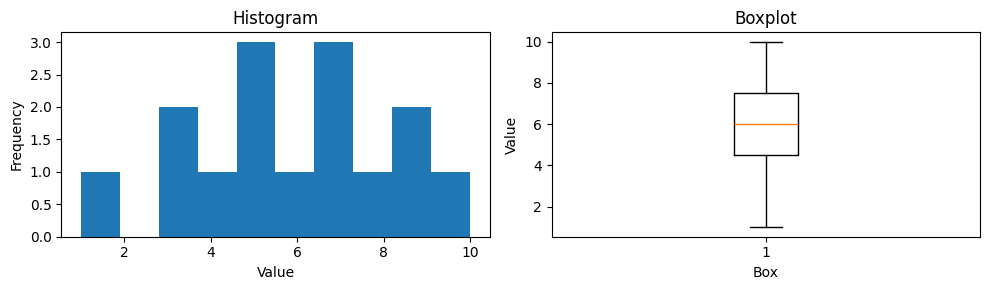

In [2]:
list_of_numbers = np.array([
    5, 4, 5, 10, 3, 5, 6, 9,
    7, 8, 7, 9, 1, 3, 7
])

plt.figure(figsize=(10, 3))

plt.subplot(1, 2, 1)
plt.hist(list_of_numbers)
plt.title('Histogram')
plt.xlabel('Value')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
plt.boxplot(list_of_numbers)
plt.title('Boxplot')
plt.xlabel('Box')
plt.ylabel('Value')

plt.tight_layout()
plt.show()

In [5]:
from typing import Required
uploaded = files.upload()
uploaded_names = list(uploaded.keys())

required_names = ['input.jpg', 'dark.png', 'mid.png', 'light.png']
missing_names = [name for name in required_names if name not in uploaded_names]

if missing_names:
    print(f"Missing Files: {', '.join(missing_names)}")

input_image = cv2.imread('input.jpg')
dark_image = cv2.imread('dark.png')
mid_image = cv2.imread('mid.png')
light_image = cv2.imread('light.png')

image = cv2.imread('input.jpg', cv2.IMREAD_GRAYSCALE)

if image is None:
  raise Exception('Image Not Found')

print('Uploaded Images:', ', '.join(uploaded_names))
print('Input Image Shape:', image.shape)

Saving dark.png to dark (1).png
Saving input.jpg to input (1).jpg
Saving light.png to light (1).png
Saving mid.png to mid (1).png
Missing Files: input.jpg, dark.png, mid.png, light.png
Uploaded Images: dark (1).png, input (1).jpg, light (1).png, mid (1).png
Input Image Shape: (600, 800)


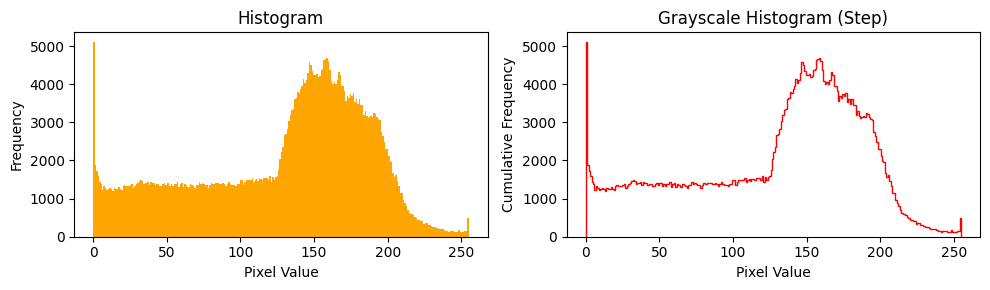

In [6]:
plt.figure(figsize=(10, 3))

plt.subplot(1, 2, 1)
plt.hist(image.ravel(), bins=256, color='orange')
plt.title('Histogram')
plt.xlabel('Pixel Value')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
plt.hist(image.ravel(), bins=256, histtype='step', color='red')
plt.title('Grayscale Histogram (Step)')
plt.xlabel('Pixel Value')
plt.ylabel('Cumulative Frequency')

plt.tight_layout()
plt.show()

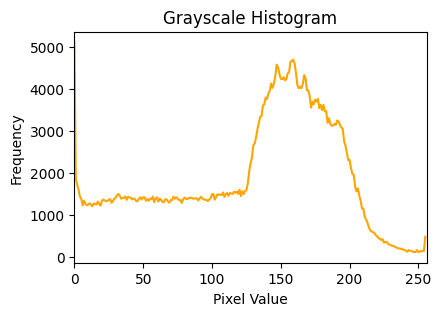

In [7]:
histogram = cv2.calcHist([image], [0], None, [256], [0, 256])

plt.figure(figsize=(10, 3))

plt.subplot(1, 2, 1)
plt.plot(histogram, color='orange')
plt.title('Grayscale Histogram')
plt.xlabel('Pixel Value')
plt.ylabel('Frequency')
plt.xlim([0, 256])

plt.show()

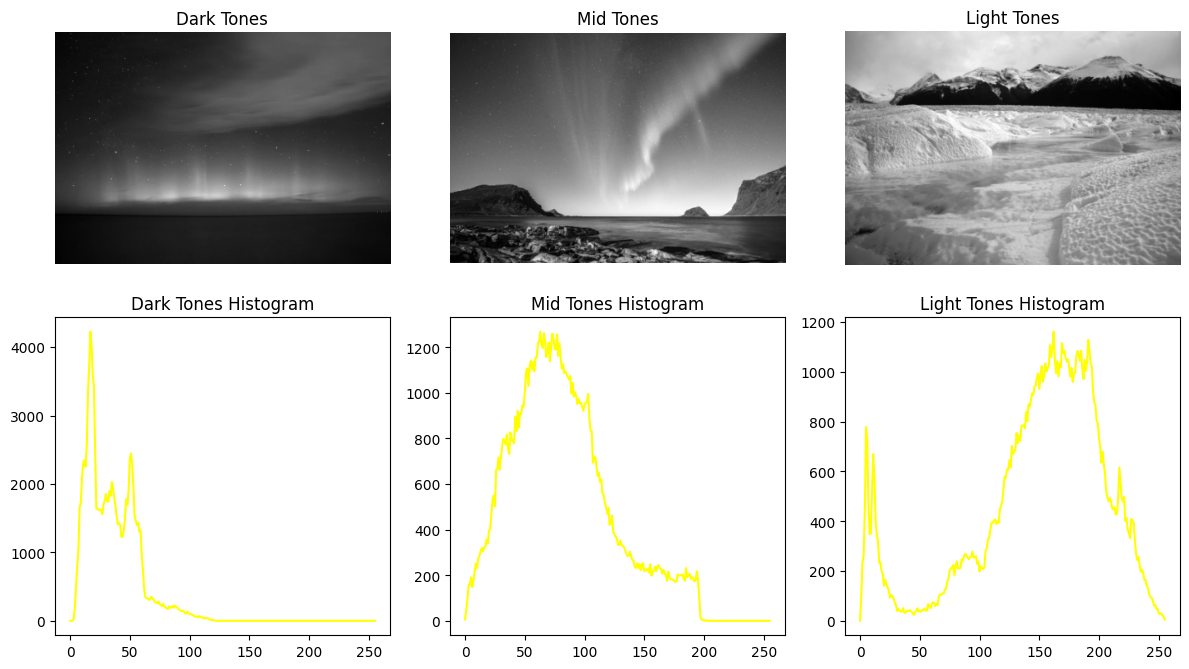

In [9]:
dark_tones = cv2.imread('dark.png')
mid_tones = cv2.imread('mid.png')
light_tones = cv2.imread('light.png')

dark_tones = cv2.cvtColor(dark_tones, cv2.COLOR_BGR2GRAY)
mid_tones = cv2.cvtColor(mid_tones, cv2.COLOR_BGR2GRAY)
light_tones = cv2.cvtColor(light_tones, cv2.COLOR_BGR2GRAY)

dark_tones_histogram = cv2.calcHist([dark_tones], [0], None, [256], [0, 256])
mid_tones_histogram = cv2.calcHist([mid_tones], [0], None, [256], [0, 256])
light_tones_histogram = cv2.calcHist([light_tones], [0], None, [256], [0, 256])

plt.figure(figsize=(12, 7))

plt.subplot(2, 3, 1)
plt.imshow(dark_tones, cmap='gray')
plt.title('Dark Tones')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(mid_tones, cmap='gray')
plt.title('Mid Tones')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(light_tones, cmap='gray')
plt.title('Light Tones')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.plot(dark_tones_histogram, color='yellow')
plt.title('Dark Tones Histogram')

plt.subplot(2, 3, 5)
plt.plot(mid_tones_histogram, color='yellow')
plt.title('Mid Tones Histogram')

plt.subplot(2, 3, 6)
plt.plot(light_tones_histogram, color='yellow')
plt.title('Light Tones Histogram')

plt.tight_layout()
plt.show()

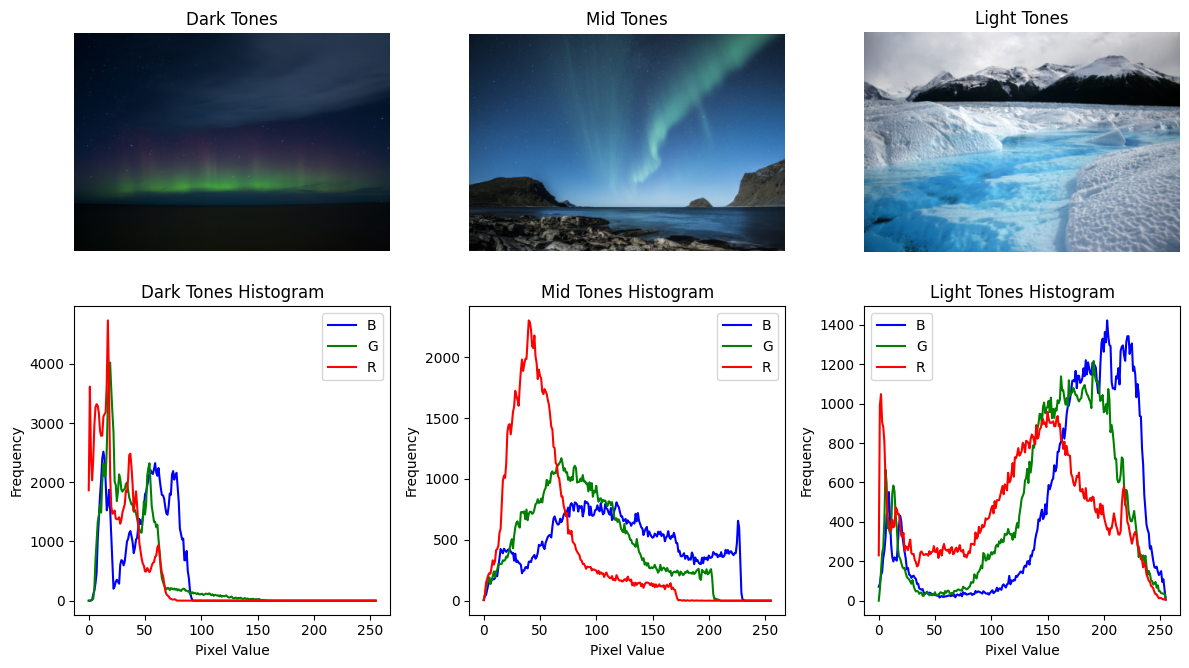

In [11]:
color_channels = ('b', 'g', 'r')

color_images = [
    ('Dark Tones', cv2.imread('dark.png')),
    ('Mid Tones', cv2.imread('mid.png')),
    ('Light Tones', cv2.imread('light.png'))
]

plt.figure(figsize=(12, 7))

for index, (title, color_image) in enumerate(color_images):

    plt.subplot(2, 3, index + 1)
    plt.imshow(cv2.cvtColor(color_image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis('off')

    plt.subplot(2, 3, index + 4)
    for channel_index, color_code in enumerate(color_channels):
        histogram = cv2.calcHist([color_image], [channel_index], None, [256], [0, 256])

        plt.plot(histogram, color=color_code, label=color_code.upper())
    plt.title(f'{title} Histogram')
    plt.xlabel('Pixel Value')
    plt.ylabel('Frequency')
    plt.legend()

plt.tight_layout()
plt.show()